In [1]:
import pandas as pd
import torch
import numpy as np
import random

In [2]:
train_data = pd.read_csv("../data/logistic_growth_train.csv")
test_data = pd.read_csv("../data/logistic_growth_test.csv")

In [3]:
train_data.head()

,L0_initial,growth_rate_a,competition_coeff_b,t_grid_0,t_grid_1,t_grid_2,t_grid_3,t_grid_4,t_grid_5,t_grid_6,...,L_t90,L_t91,L_t92,L_t93,L_t94,L_t95,L_t96,L_t97,L_t98,L_t99
0,33.090710,0.371776,0.009158,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,40.593517,40.587255,40.581092,40.575867,40.572564,40.572313,40.575604,40.578874,40.581583,40.583828
1,47.129551,0.453238,0.001284,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,352.809044,352.843019,352.868486,352.884291,352.890521,352.888510,352.880828,352.871294,352.864964,352.868141
2,19.639865,0.197991,0.001407,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,140.603070,140.609302,140.615048,140.620868,140.627370,140.635091,140.642624,140.649441,140.655610,140.661192
3,30.488209,0.459523,0.003674,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,125.033383,125.044394,125.053031,125.058881,125.061897,125.062401,125.061080,125.058988,125.057546,125.058541
4,47.760681,0.558657,0.002231,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,250.454216,250.461245,250.448120,250.416163,250.369764,250.316377,250.266520,250.233778,250.234799,250.265873


In [4]:
train_data.columns

Index(['L0_initial', 'growth_rate_a', 'competition_coeff_b', 't_grid_0',
       't_grid_1', 't_grid_2', 't_grid_3', 't_grid_4', 't_grid_5', 't_grid_6',
       ...
       'L_t90', 'L_t91', 'L_t92', 'L_t93', 'L_t94', 'L_t95', 'L_t96', 'L_t97',
       'L_t98', 'L_t99'],
      dtype='object', length=203)

In [5]:
params = train_data[['L0_initial', 'growth_rate_a', 'competition_coeff_b']].values

trajectories = train_data.filter(regex='L_t').values

x_data = torch.tensor(params, dtype=torch.float32)
y_data = torch.tensor(trajectories, dtype=torch.float32)

#Reshape for Neural Operator (Batch, Channels, Length)
x_data = x_data.unsqueeze(1) # Becomes (N, 1, 3)
y_data = y_data.unsqueeze(1) # Becomes (N, 1, 100)

print(f"Input shape: {x_data.shape}")  # e.g., torch.Size([1000, 1, 3])
print(f"Target shape: {y_data.shape}") # e.g., torch.Size([1000, 1, 100])

Input shape: torch.Size([400, 1, 3])
Target shape: torch.Size([400, 1, 100])


In [6]:
import torch
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()
scaler.fit(train_data[['L0_initial', 'growth_rate_a', 'competition_coeff_b']])

def prepare_logistic_data(df, scaler):
    p_cols = ['L0_initial', 'growth_rate_a', 'competition_coeff_b']
    scaled_params = scaler.transform(df[p_cols])
    x_params = torch.tensor(scaled_params, dtype=torch.float32) # [N, 3]
    
    t_cols = [c for c in df.columns if c.startswith('t_grid_')]
    # Wyciągamy wartości t_grid i dodajemy wymiar kanału: [N, 100] -> [N, 1, 100]
    grid = torch.tensor(df[t_cols].values, dtype=torch.float32).unsqueeze(1)
    
    # Trajektoria
    y_cols = [c for c in df.columns if c.startswith('L_t')]
    y = torch.tensor(df[y_cols].values, dtype=torch.float32).unsqueeze(1) # [N, 1, 100]
    
    # 4. Rozszerzenie parametrów do wymiaru siatki (N, 3) -> (N, 3, 100)
    num_steps = len(t_cols)
    x_expanded = x_params.unsqueeze(-1).repeat(1, 1, num_steps)
    
    # 5. Łączenie: [3 kanały parametrów] + [1 kanał siatki z CSV]
    # Wynik: (N, 4, 100)
    x = torch.cat([x_expanded, grid], dim=1)
    
    return x, y

x_train, y_train = prepare_logistic_data(train_data, scaler)
x_test, y_test = prepare_logistic_data(test_data, scaler)

In [7]:
from torch.utils.data import DataLoader, TensorDataset

# Create datasets
train_dataset = TensorDataset(x_train, y_train)
test_dataset = TensorDataset(x_test, y_test)

# Create loaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Single model for test

In [8]:
from neuralop.models import FNO

In [9]:
operator = FNO(
    n_modes=(32,),  
    hidden_channels=128,
    in_channels=4,
    out_channels=1
)

In [10]:
test_input = torch.randn(32, 4, 100) 
output = operator(test_input)

print(f"Input Shape: {test_input.shape}")   # [32, 4, 100]
print(f"Output Shape: {output.shape}")

Input Shape: torch.Size([32, 4, 100])
Output Shape: torch.Size([32, 1, 100])


In [11]:
print(x_train.shape) # ma wyjść [400, 4, 100]


torch.Size([400, 4, 100])


In [12]:
import torch.optim as optim
import torch.nn.functional as F

# Inicjalizacja list na historię
train_losses = []
val_losses = []

optimizer = optim.Adam(operator.parameters(), lr=1e-3)
criterion = torch.nn.MSELoss()

epochs = 20

for epoch in range(epochs):
    operator.train()
    total_loss = 0
    
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        output = operator(batch_x)
        loss = criterion(output, batch_y)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    avg_train_loss = total_loss / len(train_loader)
    train_losses.append(avg_train_loss) 
    
    total_val_loss = 0
    with torch.no_grad():
        for val_batch_x, val_batch_y in test_loader:
            val_output = operator(val_batch_x)
            v_loss = criterion(val_output, val_batch_y)
            total_val_loss += v_loss.item()
            
    avg_val_loss = total_val_loss / len(test_loader)
    val_losses.append(avg_val_loss) # Zapisujemy do listy
        
    print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {avg_train_loss:.6f} | Val Loss: {avg_val_loss:.6f}")


Epoch [1/20] | Train Loss: 9477.519494 | Val Loss: 6055.252319
Epoch [2/20] | Train Loss: 5833.164870 | Val Loss: 5828.971924
Epoch [3/20] | Train Loss: 5622.916973 | Val Loss: 5501.644836
Epoch [4/20] | Train Loss: 5059.662372 | Val Loss: 4635.948120
Epoch [5/20] | Train Loss: 3682.098426 | Val Loss: 3471.334229
Epoch [6/20] | Train Loss: 1864.871793 | Val Loss: 1160.801437
Epoch [7/20] | Train Loss: 800.779459 | Val Loss: 553.144863
Epoch [8/20] | Train Loss: 677.169776 | Val Loss: 862.736622
Epoch [9/20] | Train Loss: 539.949482 | Val Loss: 536.850938
Epoch [10/20] | Train Loss: 717.185570 | Val Loss: 1883.236649
Epoch [11/20] | Train Loss: 1370.126218 | Val Loss: 712.888840
Epoch [12/20] | Train Loss: 803.895691 | Val Loss: 715.508512
Epoch [13/20] | Train Loss: 520.359531 | Val Loss: 384.089048
Epoch [14/20] | Train Loss: 370.553785 | Val Loss: 638.270203
Epoch [15/20] | Train Loss: 244.014978 | Val Loss: 211.331197
Epoch [16/20] | Train Loss: 142.959985 | Val Loss: 117.844885
Epo

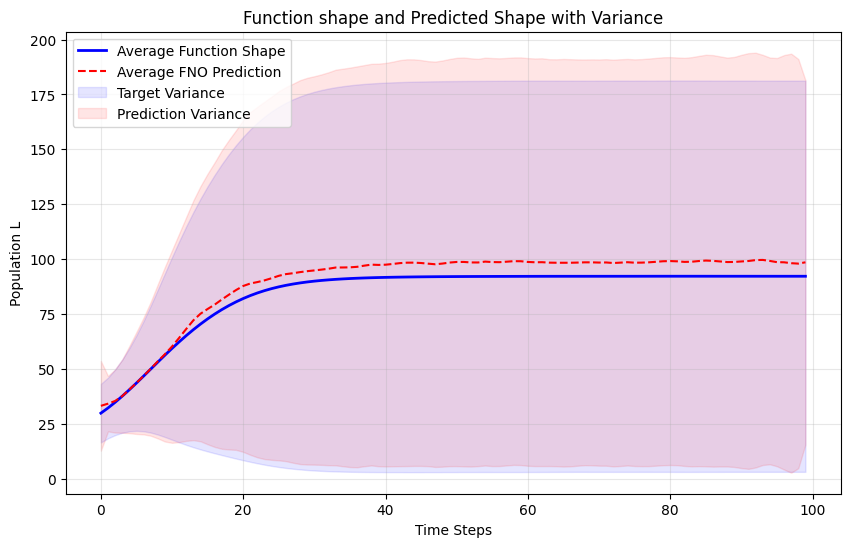

In [13]:
import numpy as np
import matplotlib.pyplot as plt
operator.eval()
with torch.no_grad():
    # 1. Get all predictions for the test set
    # Shape: [N_test, 1, 100]
    all_preds = operator(x_test).squeeze().numpy() 
    all_targets = y_test.squeeze().numpy()
    
    # 2. Calculate the Mean and Standard Deviation across all samples
    mean_target = np.mean(all_targets, axis=0)
    std_target = np.std(all_targets, axis=0)
    
    mean_pred = np.mean(all_preds, axis=0)
    std_pred = np.std(all_preds, axis=0)
    
    # 3. Plotting
    plt.figure(figsize=(10, 6))
    time_steps = np.arange(100)

    # Plot Mean Lines
    plt.plot(time_steps, mean_target, label='Average Function Shape', color='blue', linewidth=2)
    plt.plot(time_steps, mean_pred, label='Average FNO Prediction', color='red', linestyle='--')

    # Add Shaded Regions (±1 Standard Deviation)
    plt.fill_between(time_steps, mean_target - std_target, mean_target + std_target, 
                     color='blue', alpha=0.1, label='Target Variance')
    plt.fill_between(time_steps, mean_pred - std_pred, mean_pred + std_pred, 
                     color='red', alpha=0.1, label='Prediction Variance')

    plt.title("Function shape and Predicted Shape with Variance")
    plt.xlabel("Time Steps")
    plt.ylabel("Population L")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

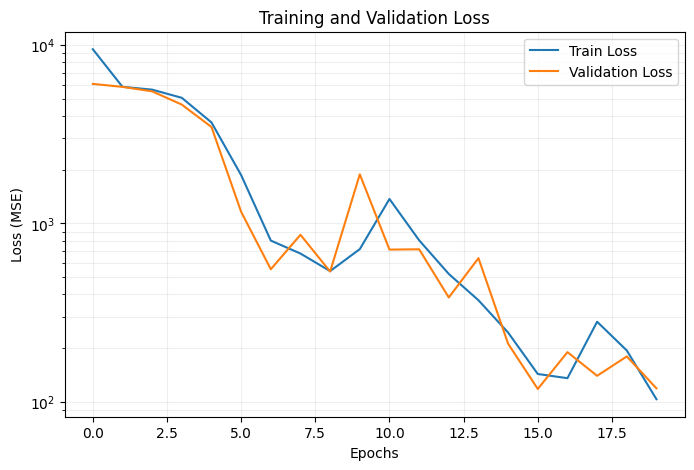

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.yscale('log') # Skala logarytmiczna jest lepsza dla strat MSE
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.2)
plt.show()

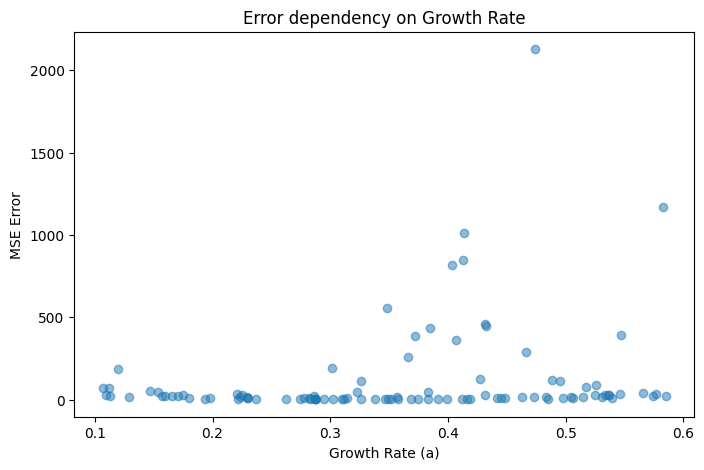

In [15]:
# Pobierz wartości 'growth_rate_a' ze zbioru testowego
rates = test_data['growth_rate_a'].values
errors = np.mean((all_preds - all_targets)**2, axis=1)

plt.figure(figsize=(8, 5))
plt.scatter(rates, errors, alpha=0.5)
plt.xlabel('Growth Rate (a)')
plt.ylabel('MSE Error')
plt.title('Error dependency on Growth Rate')
plt.show()

# Random search for best Model

In [16]:
import random
import torch
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import torch.nn.functional as F

# --- Przestrzeń parametrów do przeszukania ---
param_space = {
    'learning_rate': [1e-4, 5e-4, 1e-3, 5e-3],
    'hidden_channels': [64, 128, 256],
    'n_modes': [16, 32, 48],
    'batch_size': [16, 32, 64]
}

num_trials = 5 
results = []

def train_and_evaluate(params):
    # Rozpakowanie parametrów
    lr = params['learning_rate']
    hc = params['hidden_channels']
    nm = params['n_modes']
    bs = params['batch_size']
    
    print(f"\nTesting: LR={lr}, Hidden={hc}, Modes={nm}, BS={bs}")
    
    # Re-inicjalizacja Loadera z nowym batch_size
    train_loader = DataLoader(train_dataset, batch_size=bs, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=bs, shuffle=False)
    
    # Model i optymalizator
    model = FNO(n_modes=(nm,), hidden_channels=hc, in_channels=4, out_channels=1,non_linearity=F.relu)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = torch.nn.MSELoss()
    
    best_val_loss = float('inf')
    
    for epoch in range(10):
        model.train()
        for batch_x, batch_y in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(batch_x), batch_y)
            loss.backward()
            optimizer.step()
        
        # Walidacja
        model.eval()
        total_val_loss = 0
        with torch.no_grad():
            for val_batch_x, val_batch_y in test_loader:
                v_loss = criterion(model(val_batch_x), val_batch_y)
                total_val_loss += v_loss.item()
        
        avg_val_loss = total_val_loss / len(test_loader)
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            
    return best_val_loss

for i in range(num_trials):
    # Losowanie parametrów
    current_params = {k: random.choice(v) for k, v in param_space.items()}
    
    val_score = train_and_evaluate(current_params)
    results.append((val_score, current_params))
    print(f"Trial {i+1} finished. Best Val Loss: {val_score:.6f}")

# Sortowanie wyników od najlepszego
results.sort(key=lambda x: x[0])

print("Parametry od najlepszych")
for score, p in results:
    print(f"Loss: {score:.6f} | Params: {p}")


Testing: LR=0.0001, Hidden=256, Modes=48, BS=16
Trial 1 finished. Best Val Loss: 870.763537

Testing: LR=0.0001, Hidden=256, Modes=16, BS=16
Trial 2 finished. Best Val Loss: 1283.894108

Testing: LR=0.0005, Hidden=128, Modes=32, BS=16
Trial 3 finished. Best Val Loss: 489.510836

Testing: LR=0.0005, Hidden=128, Modes=32, BS=32
Trial 4 finished. Best Val Loss: 1232.587494

Testing: LR=0.005, Hidden=128, Modes=32, BS=16
Trial 5 finished. Best Val Loss: 171.573085
Parametry od najlepszych
Loss: 171.573085 | Params: {'learning_rate': 0.005, 'hidden_channels': 128, 'n_modes': 32, 'batch_size': 16}
Loss: 489.510836 | Params: {'learning_rate': 0.0005, 'hidden_channels': 128, 'n_modes': 32, 'batch_size': 16}
Loss: 870.763537 | Params: {'learning_rate': 0.0001, 'hidden_channels': 256, 'n_modes': 48, 'batch_size': 16}
Loss: 1232.587494 | Params: {'learning_rate': 0.0005, 'hidden_channels': 128, 'n_modes': 32, 'batch_size': 32}
Loss: 1283.894108 | Params: {'learning_rate': 0.0001, 'hidden_channel

In [17]:
# 1. Pobranie najlepszych parametrów z poprzedniego kroku
best_score, best_params = results[0]  # Wyniki posortowane rosnąco

print(f"Trening od nowa na najlepszym zestawie {best_params}")


# 2. Konfiguracja docelowa
FINAL_EPOCHS = 100  # Trenujemy znacznie dłużej

# Inicjalizacja z najlepszymi parametrami
model = FNO(
    n_modes=(best_params['n_modes'],), 
    hidden_channels=best_params['hidden_channels'], 
    in_channels=4, 
    out_channels=1
)

optimizer = optim.Adam(model.parameters(), lr=best_params['learning_rate'])
criterion = torch.nn.MSELoss()

# Dataloadery z optymalnym batch_size
train_loader = DataLoader(train_dataset, batch_size=best_params['batch_size'], shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=best_params['batch_size'], shuffle=False)

# 3. Pętla treningowa z zapisywaniem najlepszego stanu (State Dict)
best_val_loss = float('inf')
history = {'train': [], 'val': []}

for epoch in range(FINAL_EPOCHS):
    model.train()
    total_train_loss = 0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x, batch_y        
        optimizer.zero_grad()
        output = model(batch_x)
        loss = criterion(output, batch_y)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item()
    
    # Ewaluacja
    model.eval()
    total_val_loss = 0
    with torch.no_grad():
        for bx, by in test_loader:
            v_loss = criterion(model(bx), by)
            total_val_loss += v_loss.item()
    
    avg_train = total_train_loss / len(train_loader)
    avg_val = total_val_loss / len(test_loader)
    
    history['train'].append(avg_train)
    history['val'].append(avg_val)
    
    # Zapisz model, jeśli jest najlepszy do tej pory
    if avg_val < best_val_loss:
        best_val_loss = avg_val
        torch.save(model.state_dict(), 'best_fno_model.pth')
        status = " [MODEL SAVED]"
    else:
        status = ""

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{FINAL_EPOCHS}] | Train: {avg_train:.6f} | Val: {avg_val:.6f}{status}")

print(f"\nTrening zakończony. Najlepszy Val Loss: {best_val_loss:.6f}")

Trening od nowa na najlepszym zestawie {'learning_rate': 0.005, 'hidden_channels': 128, 'n_modes': 32, 'batch_size': 16}
Epoch [1/100] | Train: 7569.602563 | Val: 6370.570243 [MODEL SAVED]
Epoch [10/100] | Train: 286.243545 | Val: 351.337069
Epoch [20/100] | Train: 89.522803 | Val: 87.584844
Epoch [30/100] | Train: 48.910739 | Val: 73.264095
Epoch [40/100] | Train: 64.941548 | Val: 77.373594
Epoch [50/100] | Train: 145.928184 | Val: 103.433538
Epoch [60/100] | Train: 54.225706 | Val: 190.308204
Epoch [70/100] | Train: 54.108929 | Val: 29.252127
Epoch [80/100] | Train: 16.437718 | Val: 24.512759
Epoch [90/100] | Train: 21.406175 | Val: 30.850914
Epoch [100/100] | Train: 25.601242 | Val: 39.183199

Trening zakończony. Najlepszy Val Loss: 24.305762


In [18]:
import matplotlib.pyplot as plt

def plot_history(history, filename="loss_history.png"):
    plt.figure(figsize=(10, 5))
    plt.plot(history['train'], label='Błąd Treningowy', color='#1f77b4')
    plt.plot(history['val'], label='Błąd Walidacyjny', color='#ff7f0e')
    plt.yscale('log')
    plt.title('Krzywa uczenia FNO ($dL/dt = aL - bL^2$)')
    plt.xlabel('Epoka')
    plt.ylabel('MSE Loss (Log Scale)')
    plt.legend()
    plt.grid(True, which="both", ls="-", alpha=0.3)
    
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Zapisano: {filename}")
    plt.show()

In [19]:
def visualize_results(model, loader, num_samples=3, filename="logistic_samples.png"):
    model.eval()
    samples_x, samples_y = next(iter(loader))
    samples_x, samples_y = samples_x[:num_samples], samples_y[:num_samples]
    
    with torch.no_grad():
        preds = model(samples_x)
    
    fig, axes = plt.subplots(num_samples, 2, figsize=(12, 4 * num_samples))
    
    for i in range(num_samples):
        # Porównanie przebiegu populacji w czasie
        axes[i, 0].plot(samples_y[i].flatten(), label='Solver ODE (Target)', color='black', lw=2)
        axes[i, 0].plot(preds[i].flatten(), label='FNO (Prediction)', color='red', linestyle='--')
        axes[i, 0].set_title(f'Przykładowa ewolucja populacji L(t) - Próba {i+1}')
        axes[i, 0].set_xlabel('Kroki czasowe')
        axes[i, 0].set_ylabel('Populacja $L$')
        axes[i, 0].legend()
        
        # Błąd bezwzględny w czasie
        error = torch.abs(samples_y[i] - preds[i]).flatten().numpy()
        axes[i, 1].fill_between(range(len(error)), error, color='red', alpha=0.3)
        axes[i, 1].set_title(f'Błąd bezwzględny $|L_{{true}} - L_{{pred}}|$')
        axes[i, 1].set_xlabel('Kroki czasowe')
        
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Zapisano: {filename}")
    plt.show()

In [20]:
def visualize_results(model, loader, num_samples=3, filename="logistic_samples.png"):
    model.eval()
    samples_x, samples_y = next(iter(loader))
    samples_x, samples_y = samples_x[:num_samples], samples_y[:num_samples]
    
    with torch.no_grad():
        preds = model(samples_x)
    
    fig, axes = plt.subplots(num_samples, 2, figsize=(12, 4 * num_samples))
    
    for i in range(num_samples):
        # Porównanie przebiegu populacji w czasie
        axes[i, 0].plot(samples_y[i].flatten(), label='Solver ODE (Target)', color='black', lw=2)
        axes[i, 0].plot(preds[i].flatten(), label='FNO (Prediction)', color='red', linestyle='--')
        axes[i, 0].set_title(f'Przykładowa ewolucja populacji L(t) - Próba {i+1}')
        axes[i, 0].set_xlabel('Kroki czasowe')
        axes[i, 0].set_ylabel('Populacja $L$')
        axes[i, 0].legend()
        
        # Błąd bezwzględny w czasie
        error = torch.abs(samples_y[i] - preds[i]).flatten().numpy()
        axes[i, 1].fill_between(range(len(error)), error, color='red', alpha=0.3)
        axes[i, 1].set_title(f'Błąd bezwzględny $|L_{{true}} - L_{{pred}}|$')
        axes[i, 1].set_xlabel('Kroki czasowe')
        
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Zapisano: {filename}")
    plt.show()

In [24]:
def plot_mean_and_variance(model, loader, filename="logistic_stats.png"):
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for bx, by in loader:
            preds = model(bx)
            all_preds.append(preds)
            all_targets.append(by)
    
    all_preds = torch.cat(all_preds, dim=0).squeeze()
    all_targets = torch.cat(all_targets, dim=0).squeeze()
    
    mean_pred = all_preds.mean(dim=0)
    std_pred = all_preds.std(dim=0)
    mean_target = all_targets.mean(dim=0)
    std_target = all_targets.std(dim=0)
    
    t_axis = range(len(mean_pred))
    
    plt.figure(figsize=(12, 6))
    plt.plot(t_axis, mean_target, color='black', label='Średnia Solver ODE', lw=2)
    plt.fill_between(t_axis, mean_target - std_target, mean_target + std_target, 
                     color='black', alpha=0.1, label='Odchylenie standardowe populacji (Solver)')
    
    plt.plot(t_axis, mean_pred, color='red', linestyle='--', label='Średnia FNO', lw=2)
    plt.fill_between(t_axis, mean_pred - std_pred, mean_pred + std_pred, 
                     color='red', alpha=0.2, label='Odchylenie standardowe predykcji (FNO)')
    
    plt.title('Statystyka zbiorcza: Dynamika wzrostu populacji $L(t)$')
    plt.xlabel('Czas ($t$)')
    plt.ylabel('Populacja ($L$)')
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3)
    
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Plik {filename} został zapisany pomyślnie.")
    plt.show()

Zapisano: loss_history.png


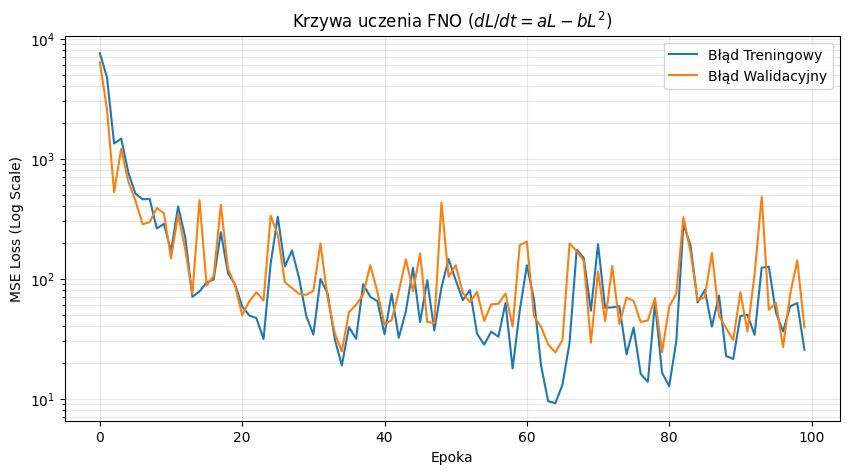

Zapisano: logistic_samples.png


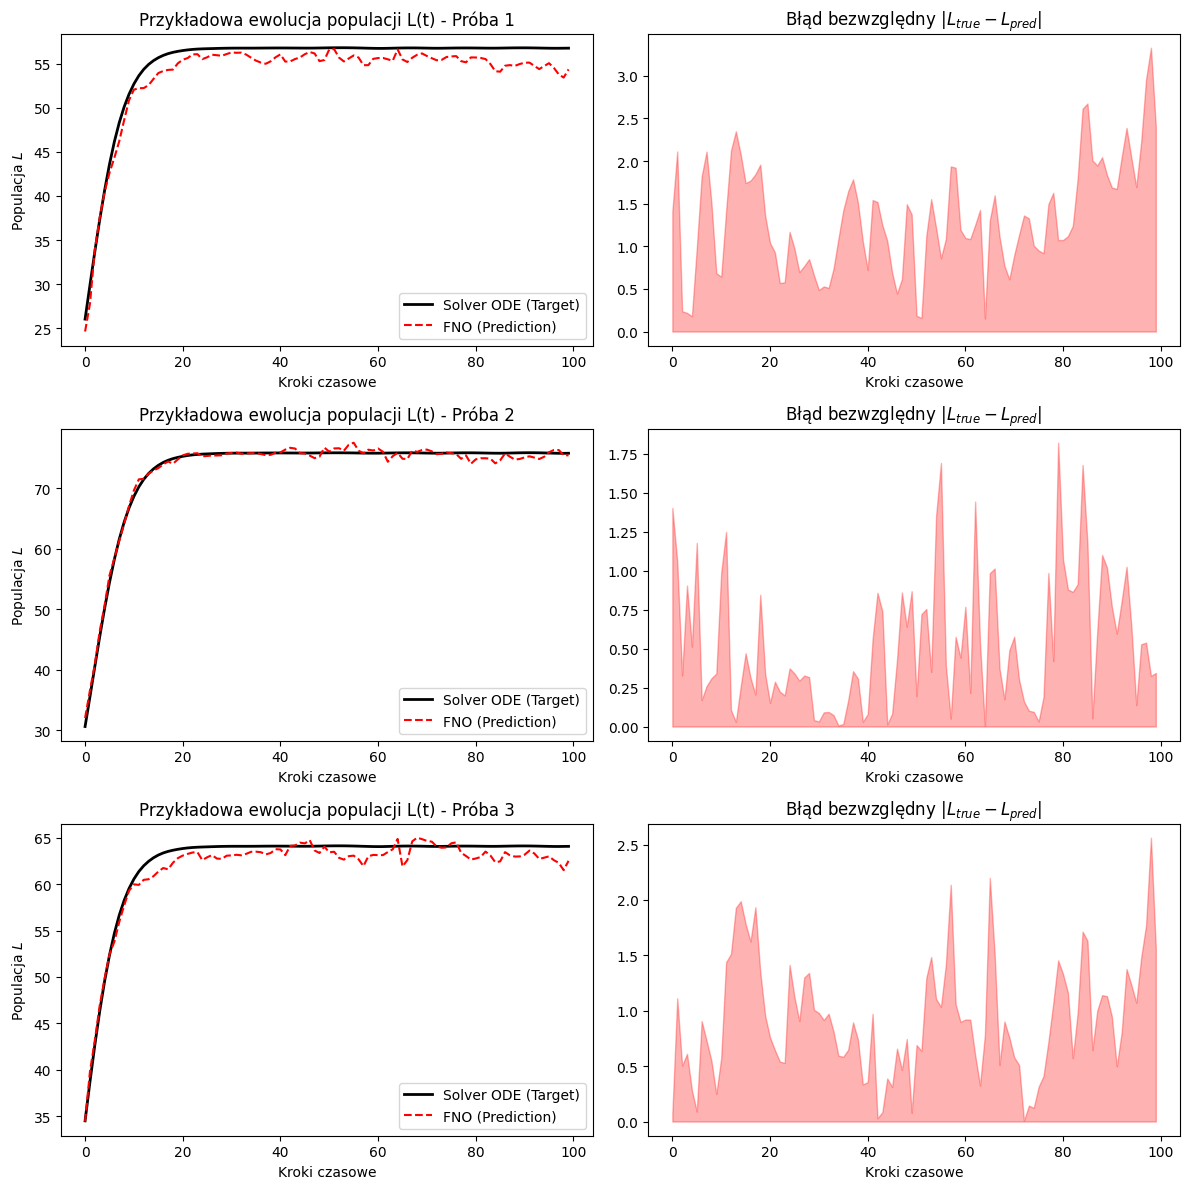

Plik logistic_stats.png został zapisany pomyślnie.


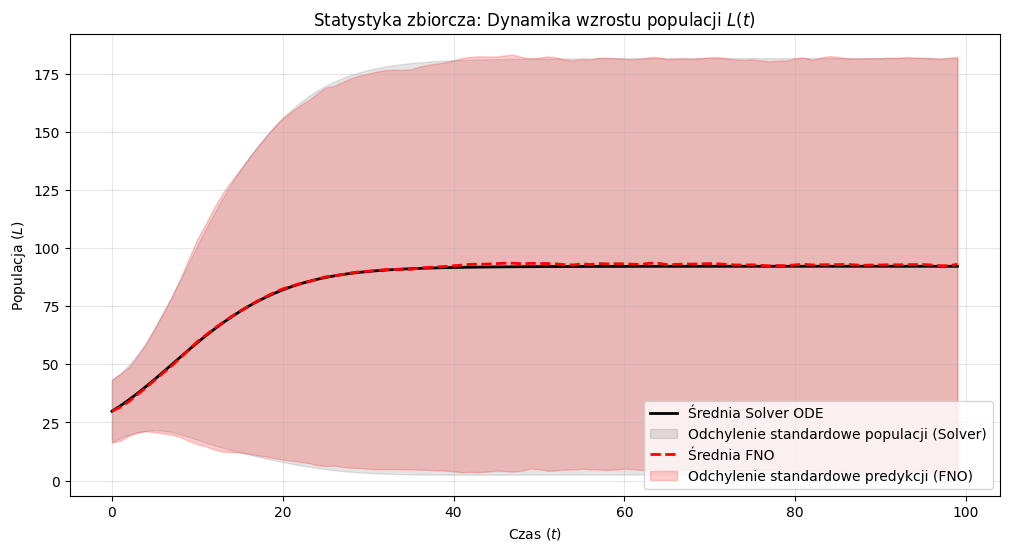

In [25]:
plot_history(history)
visualize_results(model, test_loader)
plot_mean_and_variance(model, test_loader)